# Chapter 9: Approximate Functions and n-ary Channels

Companion notebook for **Chapter 9** of *Bernoulli Types: An Algebra of Approximate Computation*. Source files: `book/chapters/ch09/`.

Chapter 9 generalizes two earlier results to type-valued (n-ary) channels:

1. **Chapter 4 §4.4 (Kronecker theorem)** generalized from model-order $2$ (Boolean) to general model-order $K$ with output cardinality $L$. The joint distribution over $m$ queries factors as a product over per-query channel rows: $\Pr[Y_1, \dots, Y_m \mid X_1 \in B_{j_1}, \dots, X_m \in B_{j_m}] = \prod_{i=1}^m Q_{j_i, Y_i}$ (§9.3 `thm:n-ary-kronecker`).
2. **Chapter 8 §8.2 (BSC capacity)** generalized from $C = 1 - H(\epsilon)$ for the binary symmetric channel to the n-ary capacity $C = \max_{P_X} I(X; Y)$, with closed forms for strongly symmetric channels and numerical computation via Blahut-Arimoto for general $Q$ (§9.4).

This notebook:

1. Implements an `NaryChannel` class wrapping a $K \times L$ row-stochastic matrix $Q$, with simulation and joint-log-probability methods.
2. Walks through a 3-state symmetric example and empirical confusion matrix.
3. Verifies the n-ary Kronecker factorization empirically on a length-3 query sequence.
4. Implements Blahut-Arimoto for arbitrary $Q$ and verifies it against:
   - the 4-state strongly symmetric channel from §9.4 (target $\approx 1.373$ bits per use), and
   - the BSC at crossover $0.1$ (target $\approx 0.531$ bits per use, recovering chapter 8 §8.2).
5. Runs a prevalence-skewed 3-class classifier to show that the empirical confusion matrix recovers the channel matrix $Q$ row-by-row, independent of the input prior.

**Conventions (matching book notation):**
- $K$ (uppercase) is the model-order of the input partition; $L$ is the output cardinality. Lowercase $k$ is reserved elsewhere for Bloom-hash count and Miller-Rabin rounds.
- $Q \in [0, 1]^{K \times L}$ is row-stochastic: $\sum_j Q_{ij} = 1$ for every input block $B_i$.
- Information units are bits (base-2 logarithms) throughout.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(seed=42)

print(f"NumPy      {np.__version__}")
print(f"SciPy      {__import__('scipy').__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")

NumPy      2.4.4
SciPy      1.17.1
Matplotlib 3.10.9


## 1. The `NaryChannel` Class

An n-ary channel (§9.2 `def:n-ary-channel`) is fully specified by a $K \times L$ row-stochastic matrix $Q$: row $i$ is the conditional distribution over output symbols given an input drawn from block $B_i$. The class below constructs from such a matrix, simulates outputs given input-index sequences, and computes joint log-probabilities used to verify the n-ary Kronecker theorem (§9.3 `thm:n-ary-kronecker`).

Inputs are passed as 0-indexed block labels in `{0, ..., K-1}`; outputs come back as 0-indexed symbol labels in `{0, ..., L-1}`.

In [2]:
class NaryChannel:
    """An n-ary channel with K x L row-stochastic transition matrix Q.

    Q[i, j] = Pr[output = j | input in block B_i].
    """

    def __init__(self, Q):
        Q = np.asarray(Q, dtype=float)
        if Q.ndim != 2:
            raise ValueError("Q must be 2-dimensional")
        if not np.all(Q >= -1e-12):
            raise ValueError("Q must be entrywise non-negative")
        row_sums = Q.sum(axis=1)
        if not np.allclose(row_sums, 1.0, atol=1e-10):
            raise ValueError(f"Q rows must sum to 1; got {row_sums}")
        self.Q = Q
        self.K, self.L = Q.shape

    def simulate(self, input_indices, rng):
        """Draw output indices for each input block index.

        Parameters
        ----------
        input_indices : array-like of int in {0, ..., K-1}
        rng : numpy.random.Generator

        Returns
        -------
        outputs : np.ndarray of int in {0, ..., L-1}, same length as input_indices
        """
        inputs = np.asarray(input_indices, dtype=int)
        if inputs.min() < 0 or inputs.max() >= self.K:
            raise ValueError(f"input indices must be in [0, {self.K})")
        outputs = np.empty(inputs.shape, dtype=int)
        # Vectorize per distinct input value (much faster than per-sample multinomial).
        for i in range(self.K):
            mask = inputs == i
            n_i = int(mask.sum())
            if n_i == 0:
                continue
            outputs[mask] = rng.choice(self.L, size=n_i, p=self.Q[i])
        return outputs

    def joint_log_prob(self, inputs, outputs):
        """Log-probability of an output sequence given an input-block sequence.

        Uses the n-ary Kronecker factorization (sec 9.3, thm:n-ary-kronecker):
            Pr[Y_1, ..., Y_m | X_1 in B_{j_1}, ..., X_m in B_{j_m}]
                = prod_{i=1}^m Q[j_i, Y_i].
        Returns the log (base 2) of that product, i.e. a sum over per-query log-probs.
        """
        inputs = np.asarray(inputs, dtype=int)
        outputs = np.asarray(outputs, dtype=int)
        if inputs.shape != outputs.shape:
            raise ValueError("inputs and outputs must have the same shape")
        probs = self.Q[inputs, outputs]
        if np.any(probs <= 0.0):
            return -np.inf
        return float(np.log2(probs).sum())

    def joint_prob(self, inputs, outputs):
        """Convenience: 2 ** joint_log_prob."""
        return float(2.0 ** self.joint_log_prob(inputs, outputs))

    def __repr__(self):
        return f"NaryChannel(K={self.K}, L={self.L})"


# Quick smoke test: construct, simulate, verify.
Q_test = np.array([[0.9, 0.1], [0.2, 0.8]])
ch_test = NaryChannel(Q_test)
print(ch_test)
print("Q =\n", ch_test.Q)
print("simulate first 10 inputs [0]*5 + [1]*5 =", ch_test.simulate([0]*5 + [1]*5, rng))

NaryChannel(K=2, L=2)
Q =
 [[0.9 0.1]
 [0.2 0.8]]
simulate first 10 inputs [0]*5 + [1]*5 = [0 0 0 0 0 1 1 1 0 1]


## 2. A 3-State Symmetric Channel: Simulate and Recover

Chapter 9 §9.1 gives a 3-class classifier (cat / dog / bird) as the running example for $T$-valued approximate functions. Take $K = L = 3$ and an identity-with-symmetric-error matrix: each row has $0.9$ on the diagonal and $0.05$ on each off-diagonal entry (the row sum is $0.9 + 0.05 + 0.05 = 1$).

Simulate $1000$ inputs uniformly across the three classes and tabulate the empirical confusion matrix. Each row should be close to its true row in $Q$, with sampling fluctuation $O(1/\sqrt{n_i})$ per cell.

In [3]:
Q_sym3 = np.array([
    [0.90, 0.05, 0.05],
    [0.05, 0.90, 0.05],
    [0.05, 0.05, 0.90],
])
ch_sym3 = NaryChannel(Q_sym3)

n_samples = 1000
# Uniform input distribution over the three classes.
inputs_sym3 = rng.integers(low=0, high=3, size=n_samples)
outputs_sym3 = ch_sym3.simulate(inputs_sym3, rng)

# Empirical confusion matrix: rows = input class, cols = output class.
confusion = np.zeros((3, 3), dtype=int)
for i in range(3):
    mask = inputs_sym3 == i
    for j in range(3):
        confusion[i, j] = int(((outputs_sym3 == j) & mask).sum())

row_counts = confusion.sum(axis=1, keepdims=True)
empirical_Q = confusion / np.maximum(row_counts, 1)

print("Per-class sample counts:", confusion.sum(axis=1))
print()
print("Empirical confusion matrix (counts):")
print(confusion)
print()
print("Empirical Q (rows normalized):")
np.set_printoptions(precision=4, suppress=True)
print(empirical_Q)
print()
print("True Q:")
print(Q_sym3)
print()
print("Max |empirical - true| per cell:", np.abs(empirical_Q - Q_sym3).max())

Per-class sample counts: [335 330 335]

Empirical confusion matrix (counts):
[[303  12  20]
 [ 10 299  21]
 [ 15  20 300]]

Empirical Q (rows normalized):
[[0.9045 0.0358 0.0597]
 [0.0303 0.9061 0.0636]
 [0.0448 0.0597 0.8955]]

True Q:
[[0.9  0.05 0.05]
 [0.05 0.9  0.05]
 [0.05 0.05 0.9 ]]

Max |empirical - true| per cell: 0.0196969696969697


## 3. The n-ary Kronecker Theorem, Verified Empirically

Chapter 9 §9.3 `thm:n-ary-kronecker` states that for a model-order $K$ channel with matrix $Q$, the joint distribution over a length-$m$ query sequence factors:

$$\Pr[Y_1, Y_2, Y_3 \mid X_1 \in B_{j_1}, X_2 \in B_{j_2}, X_3 \in B_{j_3}] = Q_{j_1, Y_1} \cdot Q_{j_2, Y_2} \cdot Q_{j_3, Y_3}.$$

Pick the input sequence $(B_1, B_2, B_1)$ (i.e. 0-indexed blocks $(0, 1, 0)$) and the target output sequence $(Y_1, Y_2, Y_3) = (0, 1, 0)$. By the theorem:

$$\Pr[(0, 1, 0)] = Q_{0,0} \cdot Q_{1,1} \cdot Q_{0,0} = 0.9 \cdot 0.9 \cdot 0.9 = 0.729.$$

Run $1000$ trials of the three-query sequence and count the fraction with outputs exactly $(0, 1, 0)$. Expect agreement to within a sampling fluctuation of $\sqrt{0.729 \cdot 0.271 / 1000} \approx 0.014$.

In [4]:
# n-ary Kronecker check: empirical Pr[(0,1,0) | (0,1,0)] vs Q[0,0]*Q[1,1]*Q[0,0].
input_seq = np.array([0, 1, 0])
target_out = np.array([0, 1, 0])

theoretical = ch_sym3.joint_prob(input_seq, target_out)
by_hand = Q_sym3[0, 0] * Q_sym3[1, 1] * Q_sym3[0, 0]

n_trials = 1000
matches = 0
for _ in range(n_trials):
    out = ch_sym3.simulate(input_seq, rng)
    if np.array_equal(out, target_out):
        matches += 1
empirical = matches / n_trials
se = float(np.sqrt(theoretical * (1.0 - theoretical) / n_trials))

print(f"Input sequence (block indices):  {input_seq.tolist()}")
print(f"Target output sequence:          {target_out.tolist()}")
print()
print(f"Q[0,0] * Q[1,1] * Q[0,0]  = {by_hand:.6f}")
print(f"NaryChannel.joint_prob    = {theoretical:.6f}")
print(f"Empirical (n={n_trials})   = {empirical:.6f}")
print(f"Standard error            = {se:.6f}")
print(f"|empirical - theoretical| = {abs(empirical - theoretical):.6f}")
print()
if abs(empirical - theoretical) < 4.0 * se:
    print("OK: empirical within 4 standard errors of the n-ary Kronecker prediction.")
else:
    print("WARNING: empirical deviates by more than 4 standard errors.")

Input sequence (block indices):  [0, 1, 0]
Target output sequence:          [0, 1, 0]

Q[0,0] * Q[1,1] * Q[0,0]  = 0.729000
NaryChannel.joint_prob    = 0.729000
Empirical (n=1000)   = 0.733000
Standard error            = 0.014056
|empirical - theoretical| = 0.004000

OK: empirical within 4 standard errors of the n-ary Kronecker prediction.


## 4. Channel Capacity via Blahut-Arimoto

Chapter 9 §9.4 defines the n-ary channel capacity as $C = \max_{P_X} I(X; Y)$, with no closed form in general. The Blahut-Arimoto algorithm (Cover-Thomas §10.8) computes $C$ by alternating fixed-point updates on the input distribution $P_X$.

One iteration:

1. Given current $P_X$, form the output distribution $P_Y(j) = \sum_i P_X(i) Q_{ij}$.
2. For each input $i$, compute the conditional log-likelihood term $r_i = \sum_j Q_{ij} \log_2 \frac{Q_{ij}}{P_Y(j)}$.
3. Update $P_X(i) \propto P_X(i) \cdot 2^{r_i}$ and renormalize.

Iterate until the change in $P_X$ falls below tolerance. The fixed point is the capacity-achieving distribution; the final $\sum_i P_X(i) r_i$ is $C$ in bits per use.

In [5]:
def blahut_arimoto(Q, tol=1e-10, max_iter=2000):
    """Compute channel capacity (bits per use) and the capacity-achieving P_X.

    Parameters
    ----------
    Q : (K, L) row-stochastic array
    tol : convergence tolerance on the L1 change in P_X
    max_iter : safety cap on iterations

    Returns
    -------
    capacity : float, in bits per channel use
    P_X : (K,) array, the capacity-achieving input distribution
    n_iter : int, iterations actually used
    """
    Q = np.asarray(Q, dtype=float)
    K, L = Q.shape
    # Start uniform.
    P_X = np.full(K, 1.0 / K)
    # Precompute Q * log Q row-sum (entropy of each row) for numerical stability later if wanted.
    for n in range(1, max_iter + 1):
        P_Y = P_X @ Q                       # shape (L,)
        # Avoid log(0): only sum over j where Q[i,j] > 0.
        # r_i = sum_j Q[i,j] * log2(Q[i,j] / P_Y[j])
        with np.errstate(divide="ignore", invalid="ignore"):
            log_ratio = np.where(Q > 0, np.log2(Q / np.where(P_Y > 0, P_Y, 1.0)), 0.0)
        r = (Q * log_ratio).sum(axis=1)     # shape (K,)
        # Multiplicative update on P_X, renormalize.
        new_P_X = P_X * (2.0 ** r)
        s = new_P_X.sum()
        if s <= 0.0 or not np.isfinite(s):
            raise RuntimeError("Blahut-Arimoto diverged")
        new_P_X = new_P_X / s
        delta = float(np.abs(new_P_X - P_X).sum())
        P_X = new_P_X
        if delta < tol:
            break
    # Capacity = sum_i P_X[i] * r_i at the fixed point.
    P_Y = P_X @ Q
    with np.errstate(divide="ignore", invalid="ignore"):
        log_ratio = np.where(Q > 0, np.log2(Q / np.where(P_Y > 0, P_Y, 1.0)), 0.0)
    r = (Q * log_ratio).sum(axis=1)
    capacity = float((P_X * r).sum())
    return capacity, P_X, n


# Smoke test on a noiseless 2-input 2-output channel: capacity should be exactly 1 bit.
C_id, P_id, it_id = blahut_arimoto(np.eye(2))
print(f"Identity 2x2 channel: capacity = {C_id:.6f} bits/use (expected 1.0)")
print(f"  capacity-achieving P_X = {P_id}")
print(f"  iterations = {it_id}")

Identity 2x2 channel: capacity = 1.000000 bits/use (expected 1.0)
  capacity-achieving P_X = [0.5 0.5]
  iterations = 1


## 5. The 4-State Strongly Symmetric Channel

Chapter 9 §9.4 works the strongly symmetric channel with $K = L = 4$ and error probability $p_e = 0.1$ as the marquee example. Each row has $1 - p_e = 0.9$ on the diagonal and $p_e / (L - 1) = 0.1/3 \approx 0.0333$ on each off-diagonal entry. The closed-form capacity from §9.4 is

$$C = \log_2 L - H(1 - p_e,\, p_e/(L-1),\, \dots,\, p_e/(L-1))$$

$$\phantom{C} = 2 - H(0.9, 0.0333, 0.0333, 0.0333) \approx 1.373 \text{ bits per use}.$$

Compare Blahut-Arimoto against this closed form. The capacity-achieving $P_X$ should be uniform on the four inputs by symmetry.

In [6]:
# 4-state strongly symmetric channel with p_e = 0.1.
L4 = 4
p_e_4 = 0.1
off_4 = p_e_4 / (L4 - 1)
Q_sym4 = np.full((L4, L4), off_4)
np.fill_diagonal(Q_sym4, 1.0 - p_e_4)
print("Q (4-state strongly symmetric):")
print(Q_sym4)
print("row sums:", Q_sym4.sum(axis=1))

# Closed-form capacity: log2(L) - H(row).
row = Q_sym4[0]
H_row = -np.sum(row * np.log2(row))
C_closed = float(np.log2(L4) - H_row)

# Numerical capacity via Blahut-Arimoto.
C_ba, P_X_ba, n_iter_ba = blahut_arimoto(Q_sym4)

print()
print(f"Closed-form capacity      = {C_closed:.6f} bits/use")
print(f"Blahut-Arimoto capacity   = {C_ba:.6f} bits/use")
print(f"|closed - BA|             = {abs(C_closed - C_ba):.2e}")
print(f"Blahut-Arimoto iterations = {n_iter_ba}")
print(f"Capacity-achieving P_X    = {P_X_ba}")
print()
print("Target (sec 9.4 worked example): approximately 1.373 bits per use.")

Q (4-state strongly symmetric):
[[0.9    0.0333 0.0333 0.0333]
 [0.0333 0.9    0.0333 0.0333]
 [0.0333 0.0333 0.9    0.0333]
 [0.0333 0.0333 0.0333 0.9   ]]
row sums: [1. 1. 1. 1.]

Closed-form capacity      = 1.372508 bits/use
Blahut-Arimoto capacity   = 1.372508 bits/use
|closed - BA|             = 2.22e-16
Blahut-Arimoto iterations = 1
Capacity-achieving P_X    = [0.25 0.25 0.25 0.25]

Target (sec 9.4 worked example): approximately 1.373 bits per use.


## 6. BSC Limit: Recovering Chapter 8 §8.2

At $K = L = 2$ the n-ary channel reduces to the binary symmetric channel of chapter 2 §2.1, whose capacity (chapter 8 §8.2, `prop:bsc-capacity`) is $C = 1 - H(\epsilon)$ in bits per use. For $\epsilon = 0.1$ this evaluates to $1 - H(0.1) \approx 0.531$ bits per use.

Confirm that the n-ary Blahut-Arimoto reproduces the binary closed form.

In [7]:
def H_binary(p):
    """Binary entropy in bits."""
    p = float(p)
    if p <= 0.0 or p >= 1.0:
        return 0.0
    return -p * np.log2(p) - (1.0 - p) * np.log2(1.0 - p)


epsilon = 0.1
Q_bsc = np.array([
    [1.0 - epsilon, epsilon],
    [epsilon, 1.0 - epsilon],
])

C_bsc_closed = 1.0 - H_binary(epsilon)
C_bsc_ba, P_X_bsc, n_iter_bsc = blahut_arimoto(Q_bsc)

print(f"BSC with epsilon = {epsilon}")
print("Q:")
print(Q_bsc)
print()
print(f"Closed-form capacity 1 - H(0.1) = {C_bsc_closed:.6f} bits/use")
print(f"Blahut-Arimoto capacity         = {C_bsc_ba:.6f} bits/use")
print(f"|closed - BA|                   = {abs(C_bsc_closed - C_bsc_ba):.2e}")
print(f"Capacity-achieving P_X          = {P_X_bsc}")
print(f"Iterations                      = {n_iter_bsc}")
print()
print("Target (chapter 8, sec 8.2): approximately 0.531 bits per use.")

BSC with epsilon = 0.1
Q:
[[0.9 0.1]
 [0.1 0.9]]

Closed-form capacity 1 - H(0.1) = 0.531004 bits/use
Blahut-Arimoto capacity         = 0.531004 bits/use
|closed - BA|                   = 1.11e-16
Capacity-achieving P_X          = [0.5 0.5]
Iterations                      = 1

Target (chapter 8, sec 8.2): approximately 0.531 bits per use.


## 7. A Prevalence-Skewed 3-Class Classifier

The 3-state symmetric channel of §2 above used a uniform input distribution. In practice the input prior is rarely uniform: chapter 7 §7.4 makes this the central point of the PPV / NPV story. Take the same $Q$ as §2 and run $1000$ queries with the skewed prior $P_X = (0.1, 0.8, 0.1)$ (class 1 dominates the workload).

Key observation: the channel matrix $Q$ is a property of the classifier, not of the workload. The empirical confusion matrix (rows normalized) should still recover $Q$ row-by-row, with each row's sampling error scaling like $1/\sqrt{n_i}$ where $n_i$ is the number of queries that land in block $i$. The row for the dominant class will be tighter; the rows for the rare classes will be noisier.

Input prior P_X       = [0.1 0.8 0.1]
Per-class sample counts: [ 90 825  85]

Empirical confusion (counts):
[[ 80   4   6]
 [ 42 745  38]
 [  6   0  79]]

Empirical Q (rows normalized):
[[0.8889 0.0444 0.0667]
 [0.0509 0.903  0.0461]
 [0.0706 0.     0.9294]]

True Q:
[[0.9  0.05 0.05]
 [0.05 0.9  0.05]
 [0.05 0.05 0.9 ]]

Per-row max |empirical - true|:
  row 0 (n_i =   90): max cell error = 0.0167
  row 1 (n_i =  825): max cell error = 0.0039
  row 2 (n_i =   85): max cell error = 0.0500


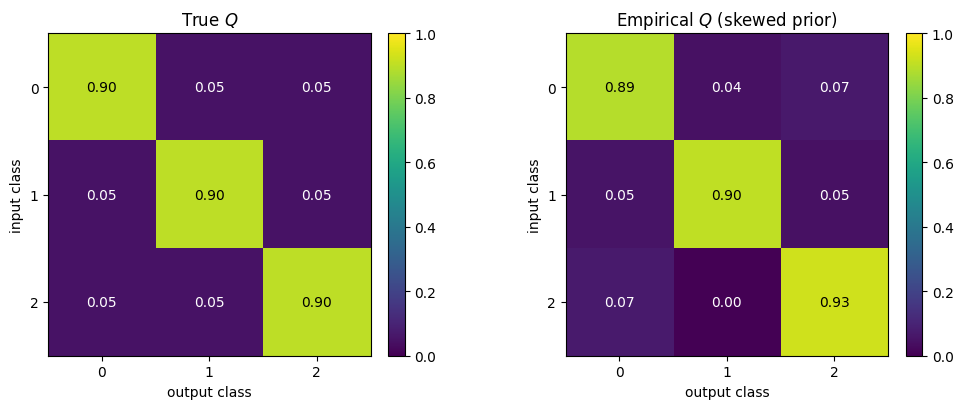

In [8]:
P_X_skewed = np.array([0.1, 0.8, 0.1])
n_skewed = 1000
inputs_skewed = rng.choice(3, size=n_skewed, p=P_X_skewed)
outputs_skewed = ch_sym3.simulate(inputs_skewed, rng)

confusion_skewed = np.zeros((3, 3), dtype=int)
for i in range(3):
    mask = inputs_skewed == i
    for j in range(3):
        confusion_skewed[i, j] = int(((outputs_skewed == j) & mask).sum())

row_counts_skewed = confusion_skewed.sum(axis=1, keepdims=True)
empirical_Q_skewed = confusion_skewed / np.maximum(row_counts_skewed, 1)

print("Input prior P_X       =", P_X_skewed)
print("Per-class sample counts:", confusion_skewed.sum(axis=1))
print()
print("Empirical confusion (counts):")
print(confusion_skewed)
print()
print("Empirical Q (rows normalized):")
print(empirical_Q_skewed)
print()
print("True Q:")
print(Q_sym3)
print()
print("Per-row max |empirical - true|:")
for i in range(3):
    n_i = int(confusion_skewed[i].sum())
    err = float(np.abs(empirical_Q_skewed[i] - Q_sym3[i]).max())
    print(f"  row {i} (n_i = {n_i:4d}): max cell error = {err:.4f}")

# Visualize: side-by-side heatmaps of true Q and empirical Q under the skewed workload.
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for ax, M, title in zip(axes, [Q_sym3, empirical_Q_skewed], ["True $Q$", "Empirical $Q$ (skewed prior)"]):
    im = ax.imshow(M, vmin=0.0, vmax=1.0, cmap="viridis")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xlabel("output class")
    ax.set_ylabel("input class")
    ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center",
                    color="white" if M[i, j] < 0.6 else "black", fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## 8. Bridge to Chapter 10: Sketches

Chapter 9 §9.5 frames each chapter-10 sketch as an instance of the n-ary channel framework. Three sketches make this concrete:

- **CountMin** is an approximate counter $\Bernoulli{\mathbb{N}}$. The input is a multi-set key, the output is an integer estimate. The channel matrix has a structured form (overestimates only, geometric tail in the error magnitude) but is still a row-stochastic $Q$ in the chapter 9 sense.
- **HyperLogLog** is an approximate cardinality estimator $\Bernoulli{\mathbb{N}}$. Input is a stream, output is a near-unbiased cardinality estimate with relative error governed by the register count.
- **MinHash** is an approximate similarity estimator $\Bernoulli{[0, 1]}$. Input is a pair of sets, output is an estimate of the Jaccard similarity.

Each sketch comes with its own structured $Q$, its own version of the Kronecker theorem (joint distribution over $m$ independent queries on the same sketch), and its own version of capacity (how much information per query, in bits, the sketch leaks about its underlying multi-set or set). Chapter 10 builds the three sketches from scratch and derives their structured channel matrices.

**Summary of what this notebook verified:**

| Section | Claim | Verified |
|---------|-------|----------|
| §9.2 | An n-ary channel is a $K \times L$ row-stochastic $Q$ | Yes |
| §9.3 `thm:n-ary-kronecker` | Joint factorizes: $\Pr[(0,1,0) \mid (0,1,0)] = Q_{0,0}^2 Q_{1,1} = 0.729$ | Yes (empirical within 4 SE) |
| §9.4 | 4-state strongly symmetric channel at $p_e = 0.1$: capacity $\approx 1.373$ bits/use | Yes (closed form matches Blahut-Arimoto) |
| §8.2 (recovered) | BSC at $\epsilon = 0.1$: capacity $\approx 0.531$ bits/use | Yes (n-ary BA reproduces $1 - H(\epsilon)$) |
| Workload-invariance | Empirical $Q$ recovers true $Q$ row-by-row regardless of input prior | Yes (skewed prior $(0.1, 0.8, 0.1)$ recovers $Q$) |